In [1]:
import pandas as pd
from pathlib import Path
import copy

In [2]:
PROJECT_PATH = Path.cwd().parent
METHU_PATH = Path(f"{PROJECT_PATH}/methu_txt")
OUT_PATH = Path(f"{PROJECT_PATH}/out_txt")

print(PROJECT_PATH, "\n", METHU_PATH, "\n", OUT_PATH)

c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio 
 c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio\methu_txt 
 c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio\out_txt


In [35]:
df_tigge = pd.DataFrame(columns=["datum","d_ta","d_tx","d_tn","d_rs"])
df_methu = df_tigge.copy()

In [46]:
print("Betöltöm a Met.hu méréseit...")
with open(f"{METHU_PATH}/BP_d.txt", "r") as file_m:
    sorok = file_m.readlines()
    sorok.pop(0)
    for sor in sorok:
        adatsor = sor.split(";")
        df_methu.loc[len(df_methu)] = [adatsor[0],float(adatsor[1]),float(adatsor[2]), float(adatsor[3]), float(adatsor[4])]
print("Kész!")

print("Betöltöm a Tigge méréseit...")
with open(f"{OUT_PATH}/Budapest_final.txt", "r") as file_t:
    sorok = file_t.readlines()
    sorok.pop(0)
    for sor in sorok:
        adatsor = sor.strip().split(';')
        df_tigge.loc[len(df_tigge)] = [adatsor[0],float(adatsor[1]),float(adatsor[2]), float(adatsor[3]), float(adatsor[4])]
print("Kész!")

Betöltöm a Met.hu méréseit...
Kész!
Betöltöm a Tigge méréseit...
Kész!


In [47]:
print(df_tigge.head(3))
print('--')
print(df_methu.head(3))

        datum  d_ta  d_tx  d_tn d_rs
0  2006-10-01  17.4  23.4  11.3  0.0
1  2006-10-02  17.6  23.0  12.2  0.0
2  2006-10-03  20.6  24.7  16.5  2.9
--
        datum  d_ta  d_tx  d_tn d_rs
0  2006-10-01  18.5  24.7  12.9  0.0
1  2006-10-02  19.5  25.1  14.5  0.0
2  2006-10-03  21.1  26.7  15.4  0.0


In [48]:
merged = df_methu.merge(df_tigge, on="datum", how="inner", suffixes=("_tigge", "_methu") )

print("Összeillesztett dataframe:")
merged.head(10)

Összeillesztett dataframe:


,datum,d_ta_tigge,d_tx_tigge,d_tn_tigge,d_rs_tigge,d_ta_methu,d_tx_methu,d_tn_methu,d_rs_methu
0,2006-10-01,18.5,24.7,12.9,0.0,17.4,23.4,11.3,0.0
1,2006-10-01,18.5,24.7,12.9,0.0,17.4,23.4,11.3,0.0
2,2006-10-01,18.5,24.7,12.9,0.0,17.4,23.4,11.3,0.0
3,2006-10-01,18.5,24.7,12.9,0.0,17.4,23.4,11.3,0.0
4,2006-10-02,19.5,25.1,14.5,0.0,17.6,23.0,12.2,0.0
5,2006-10-02,19.5,25.1,14.5,0.0,17.6,23.0,12.2,0.0
6,2006-10-02,19.5,25.1,14.5,0.0,17.6,23.0,12.2,0.0
7,2006-10-02,19.5,25.1,14.5,0.0,17.6,23.0,12.2,0.0
8,2006-10-03,21.1,26.7,15.4,0.0,20.6,24.7,16.5,2.9
9,2006-10-03,21.1,26.7,15.4,0.0,20.6,24.7,16.5,2.9


In [54]:
print("Nézzük a különbségeket:")

for adat in ["d_ta", "d_tx", "d_tn", "d_rs"]:
    print(merged[f"{adat}_methu"],merged[f"{adat}_tigge"])
    merged[f"{adat}_diff"] = merged[f"{adat}_tigge"] - merged[f"{adat}_methu"]

Nézzük a különbségeket:
0        17.4
1        17.4
2        17.4
3        17.4
4        17.6
         ... 
57715     6.0
57716     3.8
57717     3.8
57718     3.8
57719     3.8
Name: d_ta_methu, Length: 57720, dtype: object 0        18.5
1        18.5
2        18.5
3        18.5
4        19.5
         ... 
57715     7.5
57716     5.5
57717     5.5
57718     5.5
57719     5.5
Name: d_ta_tigge, Length: 57720, dtype: object


TypeError: unsupported operand type(s) for -: 'str' and 'str'

Ez így nem lesz jó, több hiba is előjön, nézzünk egy másik megoldást

In [59]:
def read_file(path):

    df = pd.read_csv(path, sep=";", skiprows=1, header = None, usecols = range(5), names=["datum", "d_ta", "d_tx", "d_tn", "d_rs"] )
    
    df["datum"] = pd.to_datetime(df["datum"])
    for col in ["d_ta", "d_tx", "d_tn", "d_rs"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

In [62]:
df_methu = read_file(f"{METHU_PATH}/BP_d.txt")
df_tigge = read_file(f"{OUT_PATH}/Budapest_final.txt")

print(df_methu.head(3))
print("--")
print(df_tigge.head(3))

       datum  d_ta  d_tx  d_tn  d_rs
0 2006-10-01  18.5  24.7  12.9   0.0
1 2006-10-02  19.5  25.1  14.5   0.0
2 2006-10-03  21.1  26.7  15.4   0.0
--
       datum  d_ta  d_tx  d_tn  d_rs
0 2006-10-01  17.4  23.4  11.3   0.0
1 2006-10-02  17.6  23.0  12.2   0.0
2 2006-10-03  20.6  24.7  16.5   2.9


In [63]:
print(df_methu.isna().sum())
print(df_tigge.isna().sum())

datum    0
d_ta     0
d_tx     0
d_tn     0
d_rs     0
dtype: int64
datum    0
d_ta     0
d_tx     0
d_tn     0
d_rs     0
dtype: int64


In [66]:
merged = df_tigge.merge(df_methu, on="datum", how="inner", suffixes=("_tigge", "_methu"))

for adat in ["d_ta", "d_tx", "d_tn", "d_rs"]:
    merged[f"{adat}_diff"] = merged[f"{adat}_tigge"] - merged[f"{adat}_methu"]

print(f"Tigge: {len(df_tigge)}, Methu: {len(df_methu)}, Összekapcsolt: {len(merged)}")
print("duplikált dátum:", merged["datum"].duplicated().sum())
print(merged.dtypes)
print(merged.filter(like="_diff").describe())

Tigge: 4810, Methu: 5206, Összekapcsolt: 4810
duplikált dátum: 0
datum         datetime64[us]
d_ta_tigge           float64
d_tx_tigge           float64
d_tn_tigge           float64
d_rs_tigge           float64
d_ta_methu           float64
d_tx_methu           float64
d_tn_methu           float64
d_rs_methu           float64
d_ta_diff            float64
d_tx_diff            float64
d_tn_diff            float64
d_rs_diff            float64
dtype: object
         d_ta_diff    d_tx_diff    d_tn_diff    d_rs_diff
count  4810.000000  4810.000000  4810.000000  4810.000000
mean     -1.250021    -1.608046    -1.778295     0.359356
std       1.403003     1.507642     1.508356     3.629564
min      -8.900000    -8.000000   -13.000000   -93.300000
25%      -2.100000    -2.600000    -2.600000     0.000000
50%      -1.300000    -1.700000    -1.700000     0.000000
75%      -0.500000    -0.700000    -0.800000     0.600000
max       6.100000     8.100000     5.300000    34.800000


In [67]:
print(merged.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.4        23.4        11.3         0.0        18.5   
1 2006-10-02        17.6        23.0        12.2         0.0        19.5   
2 2006-10-03        20.6        24.7        16.5         2.9        21.1   
3 2006-10-04        18.4        22.5        14.4         0.2        17.7   
4 2006-10-05        15.6        18.7        12.5         0.0        15.7   
5 2006-10-06        13.1        17.6         8.5         0.0        14.4   
6 2006-10-07        12.4        18.3         6.5         0.1        14.0   
7 2006-10-08        13.6        18.3         8.9         0.0        15.2   
8 2006-10-09        11.9        18.3         5.5         0.0        14.2   
9 2006-10-10        12.5        19.2         5.8         0.0        14.7   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0        24.7        12.9         0.0       -1.1       -1.3       -1.6   
1        25.1  

Vegyük ki egy külön dataframe-be csak az eltéréseket.

In [69]:
diffs = merged[["datum", "d_ta_diff", "d_tx_diff", "d_tn_diff", "d_rs_diff"]].copy()
diffs.columns = ["datum", "d_ta", "d_tx", "d_tn", "d_rs"]   # a _diff végződés fölösleges, a tábla neve már jelzi
diffs = diffs.set_index("datum").sort_index()

print(diffs.head(10))

            d_ta  d_tx  d_tn  d_rs
datum                             
2006-10-01  -1.1  -1.3  -1.6   0.0
2006-10-02  -1.9  -2.1  -2.3   0.0
2006-10-03  -0.5  -2.0   1.1   2.9
2006-10-04   0.7  -1.4  -1.2   0.2
2006-10-05  -0.1  -0.4  -0.7   0.0
2006-10-06  -1.3  -2.2  -2.4   0.0
2006-10-07  -1.6  -2.9  -1.2  -0.2
2006-10-08  -1.6  -1.6  -3.3   0.0
2006-10-09  -2.3  -3.3  -2.9   0.0
2006-10-10  -2.2  -3.0  -3.6   0.0


Probáljunk vizualizálni!

In [71]:
import matplotlib.pyplot as plt

In [85]:
m = diffs.loc["2006-10"]
print(m)

            d_ta  d_tx  d_tn  d_rs
datum                             
2006-10-01  -1.1  -1.3  -1.6   0.0
2006-10-02  -1.9  -2.1  -2.3   0.0
2006-10-03  -0.5  -2.0   1.1   2.9
2006-10-04   0.7  -1.4  -1.2   0.2
2006-10-05  -0.1  -0.4  -0.7   0.0
2006-10-06  -1.3  -2.2  -2.4   0.0
2006-10-07  -1.6  -2.9  -1.2  -0.2
2006-10-08  -1.6  -1.6  -3.3   0.0
2006-10-09  -2.3  -3.3  -2.9   0.0
2006-10-10  -2.2  -3.0  -3.6   0.0
2006-10-11  -2.4  -2.6  -3.3   0.0
2006-10-12  -1.7  -1.7  -2.5   0.0
2006-10-13  -0.7  -2.3  -0.7   0.0
2006-10-14  -0.4  -1.0  -1.8   0.0
2006-10-15  -2.1  -2.3  -3.6   0.0
2006-10-16  -1.3  -3.1  -1.8   0.0
2006-10-17  -2.3  -3.6  -3.1   0.0
2006-10-18  -2.6  -3.0  -2.5   0.0
2006-10-19  -1.4  -1.3  -2.5   0.0
2006-10-20  -0.7   0.5  -0.9   1.1
2006-10-21  -0.3  -1.1  -0.7   3.4
2006-10-22  -0.8  -1.2  -0.9   0.4
2006-10-23  -2.3  -1.4  -3.2   0.1
2006-10-24   1.7   0.0   1.0  -0.2
2006-10-25  -0.7  -2.6  -1.2   0.0
2006-10-26  -1.9  -2.3  -3.3   0.0
2006-10-27  -1.5  -3

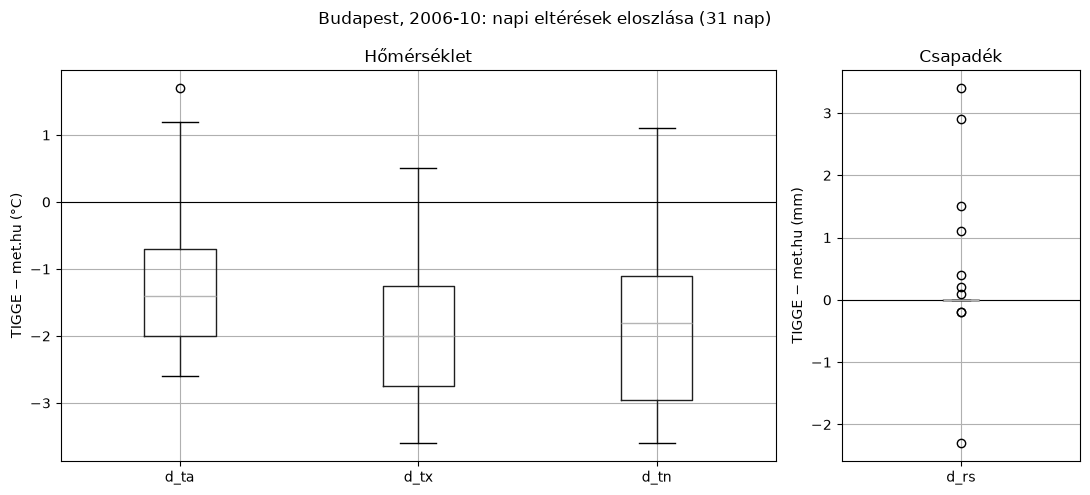

In [86]:
fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1]})

m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
ax_t.axhline(0, color="black", lw=0.8)
ax_t.set_ylabel("TIGGE − met.hu (°C)")
ax_t.set_title("Hőmérséklet")

m[["d_rs"]].boxplot(ax=ax_p)
ax_p.axhline(0, color="black", lw=0.8)
ax_p.set_ylabel("TIGGE − met.hu (mm)")
ax_p.set_title("Csapadék")

fig.suptitle(f"Budapest, 2006-10: napi eltérések eloszlása ({len(m)} nap)")
plt.tight_layout()
plt.show()

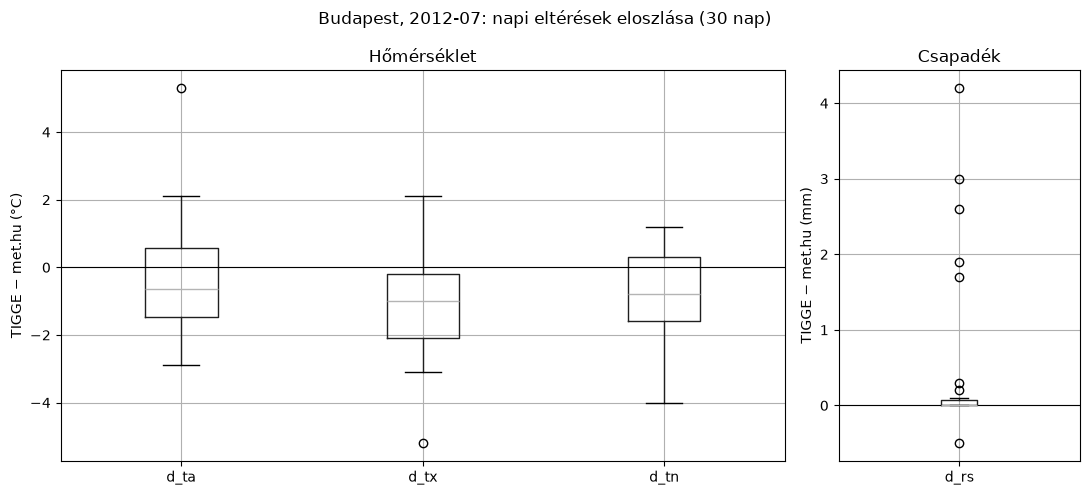

In [89]:
m = diffs.loc["2012-09"]

fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1]})

m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
ax_t.axhline(0, color="black", lw=0.8)
ax_t.set_ylabel("TIGGE − met.hu (°C)")
ax_t.set_title("Hőmérséklet")

m[["d_rs"]].boxplot(ax=ax_p)
ax_p.axhline(0, color="black", lw=0.8)
ax_p.set_ylabel("TIGGE − met.hu (mm)")
ax_p.set_title("Csapadék")

fig.suptitle(f"Budapest, 2012-07: napi eltérések eloszlása ({len(m)} nap)")
plt.tight_layout()

In [111]:

print("Függvényesítsük!")

def plot_month(diffs, year, month, city="Budapest"):
    # Szűrés külön változóba
    m = diffs[
        (diffs.index.year == year) &
        (diffs.index.month == month)
    ]

    if m.empty:
        print("A hónapról nincs adatunk!")
        return

    fig, (ax_t, ax_p) = plt.subplots(
        1, 2,
        figsize=(11, 5),
        gridspec_kw={"width_ratios": [3, 1]}
    )

    m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
    ax_t.axhline(0, color="black", lw=0.8)
    ax_t.set_ylabel("TIGGE − met.hu (°C)")
    ax_t.set_title("Hőmérséklet")

    m[["d_rs"]].boxplot(ax=ax_p)
    ax_p.axhline(0, color="black", lw=0.8)
    ax_p.set_ylabel("TIGGE − met.hu (mm)")
    ax_p.set_title("Csapadék")

    fig.suptitle(
        f"{city}, {year}-{month:02d}: "
        f"napi eltérések eloszlása ({len(m)} nap)"
    )

    plt.tight_layout()
    plt.show()


Függvényesítsük!


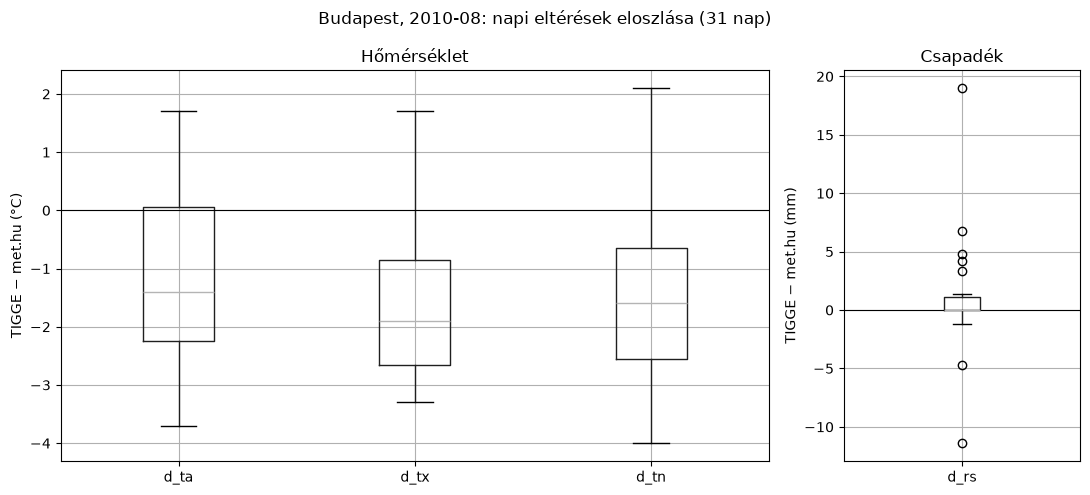

In [114]:
plot_month(diffs,2010,8)